# OPEN CV

In [2]:
!pip install opencv-python

In [3]:
import cv2
import urllib
import matplotlib.pyplot as plt

# Download an image
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/sample.png'
urllib.request.urlretrieve(url, "sample.png")


# Path to the image
image_path = "sample.png"

# Read the image in color mode
image_color = cv2.imread(image_path, cv2.IMREAD_COLOR)

# Read the image in grayscale mode
image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Transform to RGB
image_rgb = cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB)

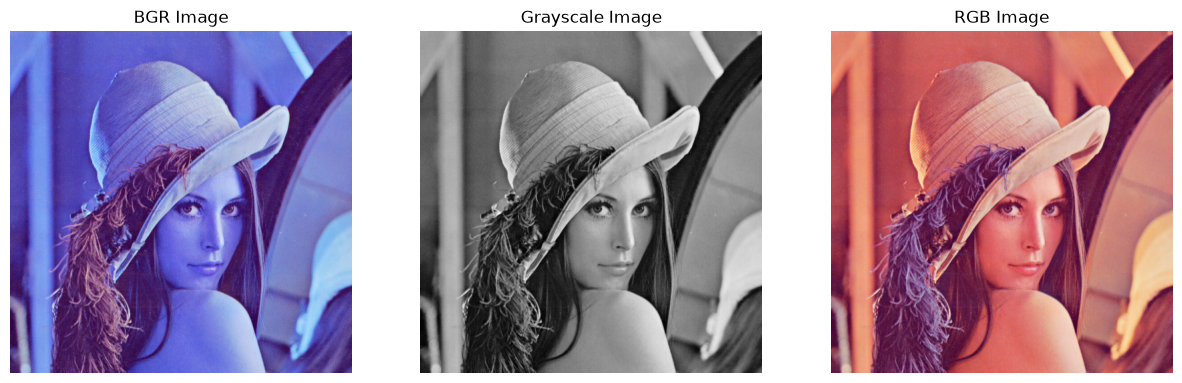

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))  # 1 row, 3 columns

# Plot original BGR image
axes[0].imshow(image_color)  # Convert BGR to RGB for correct color representation in matplotlib
axes[0].set_title("BGR Image")
axes[0].axis('off')  # Hide axis

# Plot grayscale image
axes[1].imshow(image_gray, cmap='gray')  # Grayscale image
axes[1].set_title("Grayscale Image")
axes[1].axis('off')

# Plot RGB image
axes[2].imshow(image_rgb)  # RGB image
axes[2].set_title("RGB Image")
axes[2].axis('off')

plt.show()

image shape: (300, 300, 3)


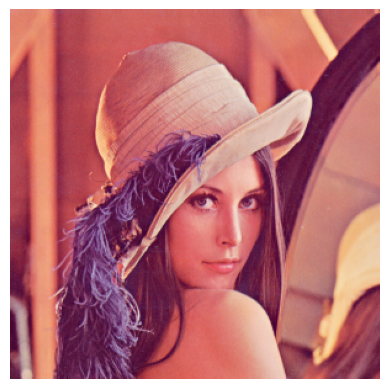

In [5]:
#manipulacione sbasicas como resize,..
resized_image_1 = cv2.resize(image_rgb, (300, 300), interpolation=cv2.INTER_LINEAR)
print(f'image shape: {resized_image_1.shape}')
plt.imshow(resized_image_1)
plt.axis('off')
plt.show()

image shape: (256, 256, 3)


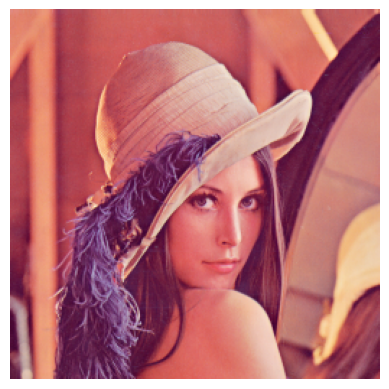

In [6]:
resized_image_2 = cv2.resize(image_rgb, (0, 0), fx=0.5, fy=0.5)
print(f'image shape: {resized_image_2.shape}')
plt.imshow(resized_image_2)
plt.axis('off')
plt.show()

[[   0.70710678    0.70710678 -106.03867197]
 [  -0.70710678    0.70710678  256.        ]]


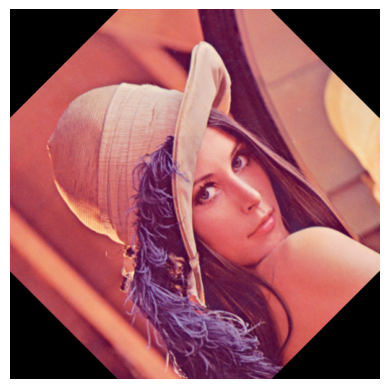

In [7]:
# rotaciones:
# Get the rotation matrix
rotation_matrix = cv2.getRotationMatrix2D((image_rgb.shape[1]/2, image_rgb.shape[0]/2), 45, 1)
print(rotation_matrix) # todo funciona con arrays
# Perform the rotation
rotated_image = cv2.warpAffine(image_rgb, rotation_matrix, (image_rgb.shape[1], image_rgb.shape[0]))

plt.imshow(rotated_image)
plt.axis('off')
plt.show()

In [8]:
from ipywidgets import interact, IntSlider, FloatSlider

# ahroa esto sirve para jugar un poco con la imagen
def rotate_image(angle, center_x, center_y, scale):
    rows, cols, _ = image_color.shape
    M = cv2.getRotationMatrix2D((center_x, center_y), angle, scale)
    rotated = cv2.warpAffine(image_color, M, (cols, rows))
    plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

interact(rotate_image, 
         angle=IntSlider(min=-180, max=180, step=1, value=0),
         center_x=FloatSlider(min=0, max=image_color.shape[1], step=0.1, value=image_color.shape[1]/2),
         center_y=FloatSlider(min=0, max=image_color.shape[0], step=0.1, value=image_color.shape[0]/2),
         scale=FloatSlider(min=0.1, max=3, step=0.1, value=1));


interactive(children=(IntSlider(value=0, description='angle', max=180, min=-180), FloatSlider(value=256.0, des…

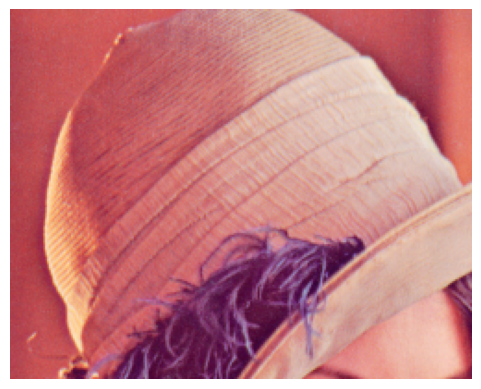

In [9]:
 # para hacer crop:
# Crop the image
cropped_image = image_rgb[50:250, 100:350]  # Crop from x=100, y=50 to x=300, y=200

plt.imshow(cropped_image)
plt.axis('off')
plt.show()

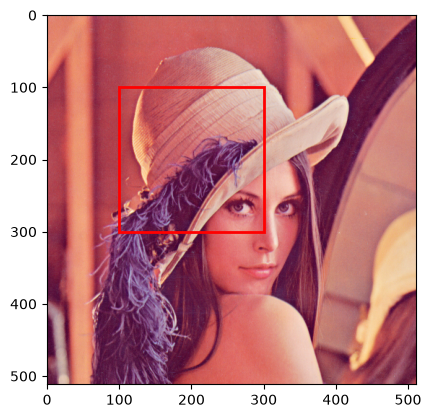

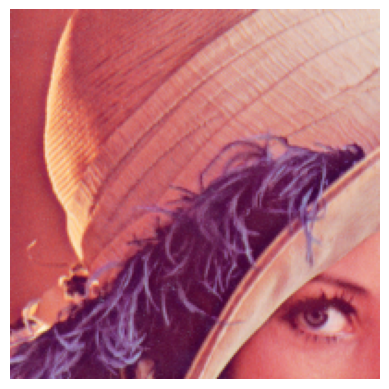

In [10]:
import matplotlib.patches as patches

# Define the crop box coordinates (x, y, width, height)
crop_box = (100, 100, 200, 200)  # (x, y, width, height)

# Create a Rectangle patch
rect = patches.Rectangle((crop_box[0], crop_box[1]), crop_box[2], crop_box[3], linewidth=2, edgecolor='r', facecolor='none')

# Plot the original image and the rectangle
fig, ax = plt.subplots()
ax.imshow(image_rgb)
ax.add_patch(rect)
plt.show()

# Define the box to crop
# Note: OpenCV uses the format (y, y+h, x, x+w) for cropping
cropped_image = image_rgb[crop_box[1]:crop_box[1] + crop_box[3], crop_box[0]:crop_box[0] + crop_box[2]]

# Display the cropped image
plt.imshow(cropped_image)
plt.axis('off')
plt.show()


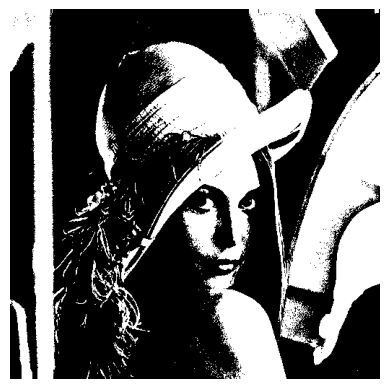

In [ ]:
# para convertir a escala de grises
gray_image = cv2.cvtColor(image_rgb, cv2.COLOR_BGR2GRAY)

# Apply basic thresholding
ret, thresh_basic = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY)

plt.imshow(thresh_basic, cmap='gray')
plt.axis('off')
plt.show()

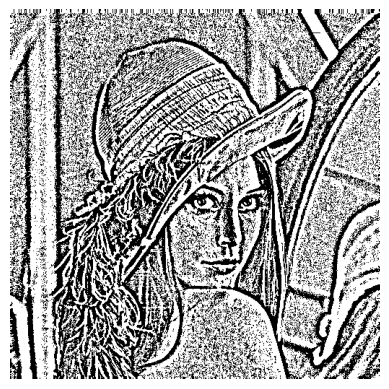

In [ ]:
# esto sirve para estar en blanco y negro pero de distinta forma a la escala de grisesq
adaptive_thresh = cv2.adaptiveThreshold(gray_image, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2)

plt.imshow(adaptive_thresh, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
from ipywidgets import interact, widgets

# aqui lo mismo para jugar un poco con el tema de grises
def interactive_thresholding(thresh_type, threshold, block_size, C):
    if thresh_type == 'Binary':
        _, th = cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)
    elif thresh_type == 'Adaptive Mean':
        th = cv2.adaptiveThreshold(gray_image, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, block_size, C)
    elif thresh_type == 'Adaptive Gaussian':
        th = cv2.adaptiveThreshold(gray_image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block_size, C)
    
    plt.imshow(th, cmap='gray')
    plt.axis('off')
    plt.show()

interact(interactive_thresholding, 
         thresh_type=widgets.Dropdown(options=['Binary', 'Adaptive Mean', 'Adaptive Gaussian'], value='Binary', description='Threshold Type:'),
         threshold=widgets.IntSlider(min=0, max=255, step=1, value=127, description='Threshold:'),
         block_size=widgets.IntSlider(min=3, max=21, step=2, value=11, description='Block Size:', disabled=False),
         C=widgets.IntSlider(min=0, max=10, value=2, description='C Value:')
        );


interactive(children=(Dropdown(description='Threshold Type:', options=('Binary', 'Adaptive Mean', 'Adaptive Ga…

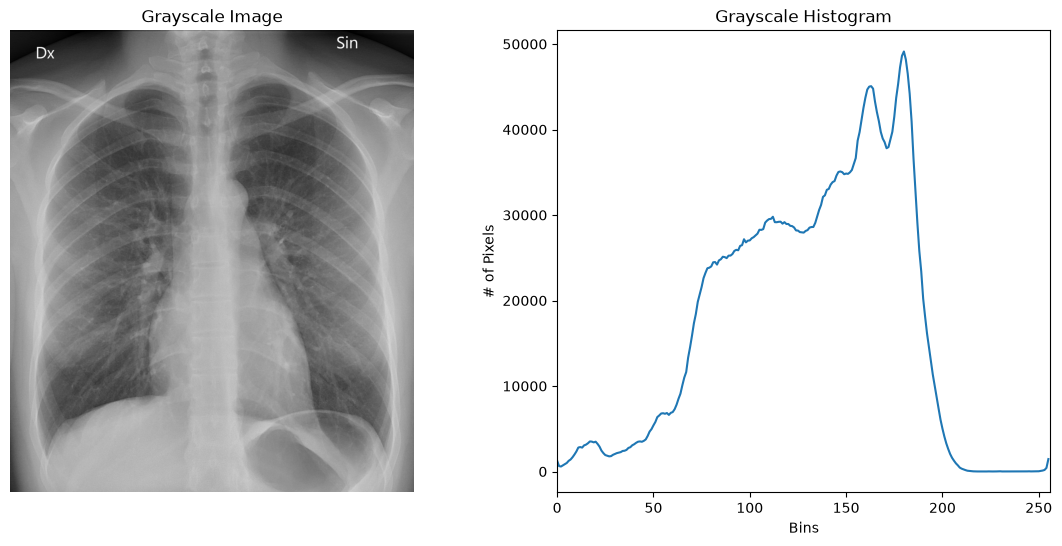

In [ ]:
# con esto mostramos un histogramas para ver la distribucion de valores de la imagen
# valores negros, 0, valores blancos, 255
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/chest_radiograph.jpg'
image_path = "x-ray.jpeg"
urllib.request.urlretrieve(url, image_path)

# Load an image in grayscale
gray_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Calculate the histogram
hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])


# Plot the image and its histogram
plt.figure(figsize=(14, 6))

# Display the image
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')

# Display the histogram
plt.subplot(1, 2, 2)
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Bins")
plt.ylabel("# of Pixels")
plt.xlim([0, 256])

plt.show()

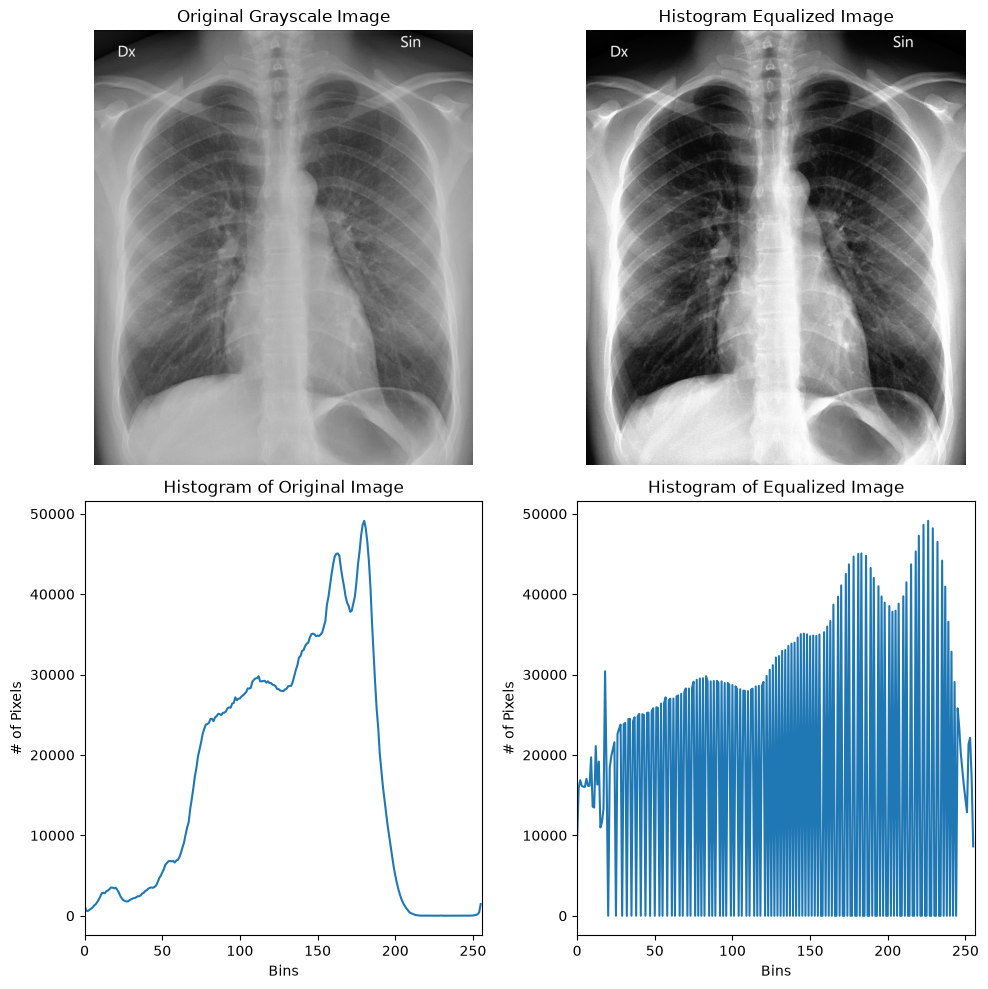

In [ ]:
equalized_image = cv2.equalizeHist(gray_image)
# histograma equalizado para asi con nuestra nueva imagen distintguis bastante mas las cosas en la imgen
# Calculate histograms
hist_original = cv2.calcHist([gray_image], [0], None, [256], [0, 256])
hist_equalized = cv2.calcHist([equalized_image], [0], None, [256], [0, 256])

# Create a 2x2 subplot
plt.figure(figsize=(10, 10))

# Display the original image
plt.subplot(2, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

# Display the histogram for the original image
plt.subplot(2, 2, 3)
plt.plot(hist_original)
plt.title("Histogram of Original Image")
plt.xlabel("Bins")
plt.ylabel("# of Pixels")
plt.xlim([0, 256])

# Display the equalized image
plt.subplot(2, 2, 2)
plt.imshow(equalized_image, cmap='gray')
plt.title("Histogram Equalized Image")
plt.axis('off')

# Display the histogram for the equalized image
plt.subplot(2, 2, 4)
plt.plot(hist_equalized)
plt.title("Histogram of Equalized Image")
plt.xlabel("Bins")
plt.ylabel("# of Pixels")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

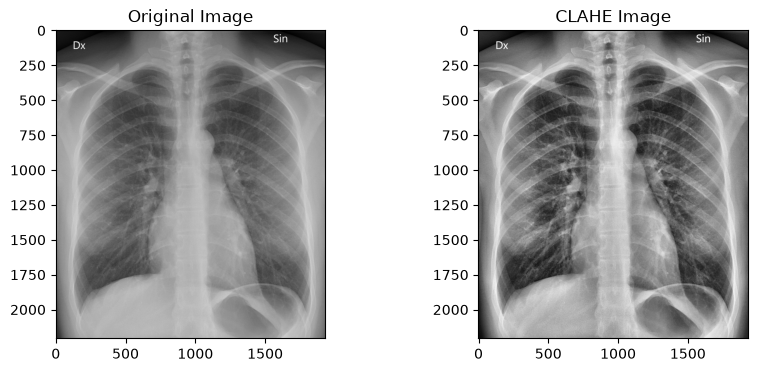

In [16]:
# Create a CLAHE object
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Apply CLAHE to the grayscale image
clahe_image = clahe.apply(gray_image)

# Display the original and CLAHE-enhanced image
plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(gray_image, cmap='gray'), plt.title('Original Image')
plt.subplot(122), plt.imshow(clahe_image, cmap='gray'), plt.title('CLAHE Image')
plt.show()

In [ ]:
# para jugar un poco con los valores para mayo o menor contraste
def view_clahe(clip_limit, tile_grid_size):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile_grid_size, tile_grid_size))
    clahe_image = clahe.apply(gray_image)

    plt.imshow(clahe_image, cmap='gray')
    plt.axis('off')
    plt.show()

interact(view_clahe, 
         clip_limit=widgets.FloatSlider(min=1, max=5, step=0.1, value=2),
         tile_grid_size=widgets.IntSlider(min=1, max=16, step=1, value=8));


interactive(children=(FloatSlider(value=2.0, description='clip_limit', max=5.0, min=1.0), IntSlider(value=8, d…